# nb1 — Five-layer simulated extraction (15 parameters, noise-free)

Synthetic reference pulse (`Simulate.simulate_reference`, L = 4096, dt = 19.4 fs), propagated in float64 through
a five-layer stack (truth: n = 3.4 / 2.5 / 5.4 / 4.2 / 1.7, κ = 0.006 / 0.004 / 0.005 / 0.001 / 0.01,
d = 70 / 200 / 100 / 200 / 50 µm).  All fifteen parameters are fitted from a hand initial guess (within
n ± 0.3, κ ± 0.005, d ± 30 % of the truth) with the scaled, coarse-to-fine L-BFGS of `RobustExtractor`
(rMSE loss; Gaussian low-pass at 0.25, 0.5, 1 THz, then full band; strong-Wolfe line search; hinge penalty
against gain), from a few starts (start 0 = hand guess, the others jittered around it); the best loss is kept.
No Bayesian pre-step.

Outputs: `figs/fig1_five_layer.*`, `results/nb1.json`.

In [1]:
import sys, os, json, time
sys.path.insert(0, '../code')
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_num_threads(int(os.environ.get('NB_THREADS', 2)))
torch.set_default_dtype(torch.float64)

from Simulate import simulate_reference
from RobustExtractor import RobustLayeredExtractor, Forward64
import paperstyle as ps
ps.apply()
os.makedirs('../figs', exist_ok=True); os.makedirs('../results', exist_ok=True)

## 1. Synthetic reference pulse and five-layer sample pulse

In [2]:
L, deltat = 4096, 19.4e-15
x_ref = simulate_reference(L, deltat).double().numpy()          # Gaussian envelope with an exponential tail
t_ps = np.arange(L) * deltat * 1e12

n_true = np.array([3.4, 2.5, 5.4, 4.2, 1.7])
k_true = np.array([0.006, 0.004, 0.005, 0.001, 0.010])
d_true = np.array([70, 200, 100, 200, 50]) * 1e-6
fwd = Forward64(x_ref, deltat)
with torch.no_grad():
    y_sample = fwd(torch.tensor(n_true), -torch.tensor(k_true), torch.tensor(d_true)).numpy()   # Forward64: n + i k, k = −κ
print(f'L = {L}, dt = {deltat*1e15:.1f} fs, window {t_ps[-1]:.1f} ps; total optical path sum(n d) = {np.sum(n_true*d_true)*1e6:.1f} um')
print('round-trip time 2 n d / c per layer (ps):', np.round(2 * n_true * d_true / 2.99792458e8 * 1e12, 2))

L = 4096, dt = 19.4 fs, window 79.4 ps; total optical path sum(n d) = 2203.0 um
round-trip time 2 n d / c per layer (ps): [1.59 3.34 3.6  5.6  0.57]


## 2. Hand initial guess (within n ± 0.3, κ ± 0.005, d ± 30 %)

In [3]:
n_init = np.array([3.2, 2.7, 5.2, 4.4, 1.9])
k_init = np.array([0.004, 0.006, 0.003, 0.004, 0.007])
d_init = np.array([85, 170, 120, 160, 60]) * 1e-6
assert np.all(np.abs(n_init - n_true) <= 0.3) and np.all(np.abs(k_init - k_true) <= 0.005) and np.all(np.abs(d_init / d_true - 1) <= 0.3)
layers_init = [(n_init[i] - 1j * k_init[i], d_init[i]) for i in range(5)]     # RobustExtractor convention: n + i k with k < 0 = loss
with torch.no_grad():
    y_init = fwd(torch.tensor(n_init), -torch.tensor(k_init), torch.tensor(d_init)).numpy()
loss_init = float(np.sqrt(np.mean((y_init - y_sample) ** 2)))
print(f'rMSE of the initial guess: {loss_init:.3e}')

rMSE of the initial guess: 1.150e-02


## 3. Coarse-to-fine L-BFGS from a few starts (start 0 = hand guess)

In [4]:
N_STARTS, SEED = 4, 0
SCHEDULE, MAX_ITER = (0.25e12, 0.5e12, 1.0e12, None), 300
RE = RobustLayeredExtractor(x_ref, y_sample, deltat, layers_init)
rng = np.random.default_rng(SEED)
starts = [RE._pack(RE.n0, RE.k0, RE.d0)]
for _ in range(N_STARTS - 1):                      # same jitter as RobustLayeredExtractor.fit: n ± 0.15, d x exp(± 0.35), k in [−0.01, 0]
    n = RE.n0 + torch.tensor(rng.uniform(-0.15, 0.15, 5))
    d = RE.d0 * torch.exp(torch.tensor(rng.uniform(-0.35, 0.35, 5)))
    k = torch.tensor(rng.uniform(-0.01, 0.0, 5))
    starts.append(RE._pack(n, k, d))
start_results = []
for s, x0 in enumerate(starts):
    n_eval0 = len(RE.loss_history); t0 = time.time()
    print(f'start {s}:')
    x, l = RE.fit_from(x0, SCHEDULE, MAX_ITER, verbose=True)
    wall = time.time() - t0; n_eval = len(RE.loss_history) - n_eval0
    start_results.append(dict(x=x, loss=l, evals=n_eval, wall=wall, layers=RE._to_layers(x)))
    print(f'  -> loss {l:.3e}, {n_eval} evaluations, {wall:.1f} s')
best = int(np.argmin([r['loss'] for r in start_results]))
RE.best_x = start_results[best]['x']; RE.best_loss = start_results[best]['loss']
layers_fit = start_results[best]['layers']
n_fit = np.array([l[0].real for l in layers_fit]); k_fit = -np.array([l[0].imag for l in layers_fit]); d_fit = np.array([l[1] for l in layers_fit])
y_fit = RE.simulate()
resid = y_sample - y_fit
print(f'\nbest start: {best}, rMSE {RE.best_loss:.3e}')

start 0:


    low-pass 0.25 THz      -> loss 2.407e-05  (112 evaluations)


    low-pass 0.50 THz      -> loss 1.939e-05  (76 evaluations)


    low-pass 1.00 THz      -> loss 1.446e-05  (115 evaluations)


    full band              -> loss 7.937e-08  (58 evaluations)
  -> loss 7.937e-08, 361 evaluations, 55.2 s
start 1:


    low-pass 0.25 THz      -> loss 2.461e-05  (349 evaluations)


... (7 outputs left out)

    low-pass 0.25 THz      -> loss 2.418e-05  (110 evaluations)


    low-pass 0.50 THz      -> loss 1.926e-05  (97 evaluations)


    low-pass 1.00 THz      -> loss 1.446e-05  (67 evaluations)


    full band              -> loss 1.260e-07  (320 evaluations)
  -> loss 1.260e-07, 594 evaluations, 94.8 s

best start: 1, rMSE 5.098e-08


## 4. Errors

In [5]:
err_n = 100 * np.abs(n_fit - n_true) / n_true
err_k = 100 * np.abs(k_fit - k_true) / k_true
err_d = 100 * np.abs(d_fit - d_true) / d_true
print(f"{'layer':>5} {'n true':>7} {'n fit':>9} {'err %':>8} | {'k true':>7} {'k fit':>9} {'err %':>8} | {'d true':>7} {'d fit':>9} {'err %':>8}")
for i in range(5):
    print(f"{i+1:5d} {n_true[i]:7.3f} {n_fit[i]:9.5f} {err_n[i]:8.4f} | {k_true[i]:7.4f} {k_fit[i]:9.6f} {err_k[i]:8.3f} | {d_true[i]*1e6:7.1f} {d_fit[i]*1e6:9.4f} {err_d[i]:8.4f}")
print(f'max error: n {err_n.max():.2e} %, kappa {err_k.max():.2e} %, d {err_d.max():.2e} %')

layer  n true     n fit    err % |  k true     k fit    err % |  d true     d fit    err %
    1   3.400   3.40001   0.0002 |  0.0060  0.006002    0.029 |    70.0   69.9998   0.0003
    2   2.500   2.50000   0.0002 |  0.0040  0.004000    0.006 |   200.0  199.9997   0.0001
    3   5.400   5.40000   0.0001 |  0.0050  0.005003    0.057 |   100.0  100.0000   0.0000
    4   4.200   4.20000   0.0000 |  0.0010  0.001003    0.271 |   200.0  200.0000   0.0000
    5   1.700   1.69998   0.0011 |  0.0100  0.009980    0.200 |    50.0   50.0010   0.0021
max error: n 1.07e-03 %, kappa 2.71e-01 %, d 2.06e-03 %


## 5. Figure 1

saved ../figs/fig1_five_layer.png + .pdf  [6.58 x 6.95 cm; placed at 6.6 cm the smallest font prints at 7.02 pt]


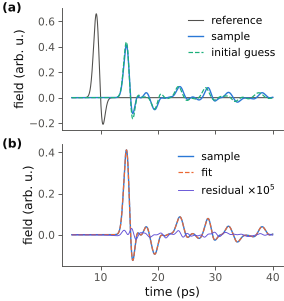

In [6]:
# half-width figure (R25): exported at 6.6 cm, all fonts >= 7 pt at that size; the two panels are stacked
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.6 / 2.54, 7.0 / 2.54), sharex=True, gridspec_kw=dict(hspace=0.12, left=0.2, right=0.98, top=0.97, bottom=0.12))
w = (t_ps > 5) & (t_ps < 40)
ax1.plot(t_ps[w], x_ref[w], color=ps.ROLE['reference'], lw=0.7, label='reference')
ax1.plot(t_ps[w], y_sample[w], color=ps.ROLE['sample'], lw=0.9, label='sample')
ax1.plot(t_ps[w], y_init[w], color=ps.ROLE['init'], lw=0.8, ls='--', label='initial guess')
ax1.set_ylabel('field (arb. u.)'); ax1.legend(loc='upper right', fontsize=7, handlelength=1.4)
ax2.plot(t_ps[w], y_sample[w], color=ps.ROLE['sample'], lw=0.9, label='sample')
ax2.plot(t_ps[w], y_fit[w], color=ps.ROLE['fit'], lw=0.8, ls='--', label='fit')
rexp = int(np.round(np.log10(0.15 * np.abs(y_sample).max() / np.abs(resid).max())))
ax2.plot(t_ps[w], 10.0 ** rexp * resid[w], color=ps.ROLE['residual'], lw=0.6, label=f'residual $\\times10^{{{rexp}}}$')
ax2.set_xlabel('time (ps)'); ax2.set_ylabel('field (arb. u.)'); ax2.legend(loc='upper right', fontsize=7, handlelength=1.4)
for a in (ax1, ax2): ps.despine(a)
ps.panel_label(ax1, 'a', x=-0.27, y=0.95); ps.panel_label(ax2, 'b', x=-0.27, y=0.95)
ps.savefig(fig, '../figs/fig1_five_layer', target_width_cm=6.6)
plt.show()

## 6. Results JSON

In [7]:
results = dict(
    notebook='nb1_five_layer_simulation.ipynb',
    simulation=dict(L=L, dt_fs=deltat * 1e15, window_ps=float(t_ps[-1]), pulse='simulate_reference (Gaussian envelope 0.8 ps, 1 ps exponential tail)',
                    precision='float64', noise='none'),
    truth=dict(n=n_true, kappa=k_true, d_um=d_true * 1e6, nd_um=n_true * d_true * 1e6, total_nd_um=float(np.sum(n_true * d_true) * 1e6),
               round_trip_ps=2 * n_true * d_true / 2.99792458e8 * 1e12),
    initial_guess=dict(n=n_init, kappa=k_init, d_um=d_init * 1e6, bounds='n ± 0.3, kappa ± 0.005, d ± 30 %', rmse=loss_init),
    protocol=dict(optimizer='coarse-to-fine L-BFGS (RobustExtractor): strong-Wolfe line search, history 50, lr 1, max 300 iterations per stage',
                  loss='rMSE + hinge penalty lambda*sum(relu(k)) (lambda = 1) against gain', lowpass_schedule_THz=[0.25, 0.5, 1.0, None],
                  scaling='n = n0 + 0.1 x, kappa = kappa0 + 0.005 x, d = d0 exp(0.1 x)', n_starts=N_STARTS, seed=SEED,
                  start_jitter='start 0 = hand guess; others n ± 0.15, d x exp(± 0.35), kappa in [0, 0.01]'),
    starts=[dict(index=s, loss=r['loss'], function_evaluations=r['evals'], wall_time_s=r['wall'],
                 n=[l[0].real for l in r['layers']], kappa=[-l[0].imag for l in r['layers']], d_um=[l[1] * 1e6 for l in r['layers']]) for s, r in enumerate(start_results)],
    best=dict(start=best, rmse=RE.best_loss, function_evaluations=start_results[best]['evals'], wall_time_s=start_results[best]['wall'],
              total_function_evaluations_all_starts=int(len(RE.loss_history)), total_wall_time_s=float(sum(r['wall'] for r in start_results)),
              n=n_fit, kappa=k_fit, d_um=d_fit * 1e6),
    errors_percent=dict(n=err_n, kappa=err_k, d=err_d, max_n=float(err_n.max()), max_kappa=float(err_k.max()), max_d=float(err_d.max())),
    residual=dict(rmse=float(np.sqrt(np.mean(resid ** 2))), max_abs=float(np.abs(resid).max()), sample_peak=float(np.abs(y_sample).max())),
)
results['loop1_checks'] = dict(figure_export=ps.FONT_LOG, note='loop 1: fig1 redrawn as a half-width (6.6 cm) figure, panels stacked')
json.dump(ps.to_jsonable(results), open('../results/nb1.json', 'w'), indent=1)
print('wrote ../results/nb1.json')

wrote ../results/nb1.json
